# Experimento A — Red FHN con control $u=\lambda=\pm k$

**Hipótesis numérica:** con el signo literal de (3), el control $\lambda=-k$ (difusivo atractivo) tiende a reducir la dispersión de estados en una red homogénea y conexa; $\lambda=+k$ (repulsivo) puede dificultar la sincronización.

Usamos **exactamente** las ecuaciones (3)–(4) del PDF:

$$\dot v_i=v_i-\frac{v_i^3}{3}-w_i+I+\frac{\lambda}{N}\sum_{j=1}^N A_{ij}(v_i-v_j),\qquad \tau\dot w_i=v_i+a-bw_i.$$

- Se fija $I=0.6$ y se varía $\lambda=\pm k$, $k\in[0,1]$ (21 valores por signo).
- Red completa de $N=8$ neuronas idénticas; misma condición inicial en todos los experimentos.
- $D(t)=\sqrt{\frac1N\sum_i [(v_i-\bar v)^2+\tau(w_i-\bar w)^2]}$: **medida principal** de sincronización completa. $D=0$ implica estados idénticos.
- $R(t)=\left|N^{-1}\sum_i e^{i\theta_i(t)}\right|$, con $\theta_i=\mathrm{atan2}(w_i-w^*,v_i-v^*)$: medida **geométrica exploratoria**; cerca de un equilibrio no oscilatorio no equivale a la fase dinámica de Kuramoto.

Se muestran figuras en el notebook; **no se guardan imágenes**. Instalación: `pip install numpy scipy matplotlib ipython ipywidgets`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import brentq
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

try:
    import ipywidgets as widgets
    from ipywidgets import interact
    HAY_WIDGETS = True
except ImportError:
    HAY_WIDGETS = False

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.25})

## 1. Modelo, parámetros, red y observables
Todas las funciones se definen aquí: no se importa ningún archivo de `src/`.

In [2]:
# === Todas las funciones necesarias están definidas en este notebook ===
# Ecuaciones (3)-(4) del enunciado: el acoplamiento tiene signo +lambda*(v_i-v_j).
PARAM = {"a": 0.7, "b": 0.8, "tau": 12.5}
N = 8
A = np.ones((N, N)) - np.eye(N)  # Grafo completo no dirigido, A_ii = 0.
GRADOS = A.sum(axis=1)

# Mismas condiciones iniciales para TODOS los ensayos (+k, -k y todos los k).
rng = np.random.default_rng(2026)
V0 = rng.uniform(-1.9, 1.4, N)
W0 = rng.uniform(-0.55, 0.75, N)
X0 = np.concatenate([V0, W0])

T_FINAL = 110.0
T_EVAL = np.linspace(0, T_FINAL, 1101)
K_VALORES = np.linspace(0.0, 1.0, 21)


def fhn_red(t, x, lam, corriente, A=A, parametros=PARAM):
    """Ecuaciones (3) y (4) literales, para corrientes escalares o por neurona."""
    n = A.shape[0]
    v, w = x[:n], x[n:]
    a, b, tau = parametros['a'], parametros['b'], parametros['tau']
    grados = A.sum(axis=1)
    acoplamiento = (lam / n) * (grados * v - A @ v)
    dv = v - (v**3)/3 - w + corriente + acoplamiento
    dw = (v + a - b*w) / tau
    return np.concatenate([dv, dw])


def simular(lam, corriente, x0=X0, t_eval=T_EVAL):
    resultado = solve_ivp(
        fhn_red, (float(t_eval[0]), float(t_eval[-1])), x0,
        t_eval=t_eval, args=(lam, corriente), method='DOP853',
        rtol=1e-7, atol=1e-9
    )
    if not resultado.success:
        raise RuntimeError(resultado.message)
    n = len(x0) // 2
    return {"t": resultado.t, "v": resultado.y[:n], "w": resultado.y[n:]}


def equilibrio_individual(corriente):
    """Equilibrio de una sola neurona, con I constante y sin acoplamiento."""
    a, b = PARAM['a'], PARAM['b']
    # Aquí b>0; la raíz es única para 0<b<1.
    v = brentq(lambda q: q - q**3/3 - (q + a)/b + corriente, -10, 10)
    return v, (v+a)/b


def metricas(sol, corriente):
    """D: dispersión de estados; R: coherencia geométrica de fases, orientativa."""
    v, w = sol['v'], sol['w']
    dv, dw = v - v.mean(axis=0), w - w.mean(axis=0)
    D = np.sqrt(np.mean(dv**2 + PARAM['tau'] * dw**2, axis=0))
    veq, weq = equilibrio_individual(corriente)
    ang = np.arctan2(w-weq, v-veq)
    R = np.abs(np.mean(np.exp(1j*ang), axis=0))
    # Amplitud de la señal promedio en el tercio final; un diagnóstico, no una prueba de ciclo.
    inicio = int(0.70 * v.shape[1])
    senal = v.mean(axis=0)[inicio:]
    amplitud = float(senal.max() - senal.min())
    return {"D": D, "R": R, "D_final": float(D[inicio:].mean()),
            "R_final": float(R[inicio:].mean()), "amplitud_media": amplitud}


def curvas_ejemplo(sol, titulo, corriente):
    m = metricas(sol, corriente)
    t, v, w = sol['t'], sol['v'], sol['w']
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
    for i in range(v.shape[0]):
        axes[0].plot(t, v[i], lw=1.0, alpha=0.85)
    axes[0].set(xlabel='t', ylabel=r'$v_i(t)$', title='Potenciales')
    axes[1].plot(t, m['D'], color='C1', lw=2, label='Dispersión D')
    axes[1].set(xlabel='t', ylabel='D(t)', title='Dispersión entre neuronas')
    axes[2].plot(t, m['R'], color='C2', lw=2)
    axes[2].set(xlabel='t', ylabel='R(t)', ylim=(-.03, 1.03), title='Coherencia geométrica')
    fig.suptitle(titulo)
    fig.tight_layout()
    plt.show()
    print(f"D promedio (último 30%): {m['D_final']:.4f} | R promedio: {m['R_final']:.4f} | amplitud de media v: {m['amplitud_media']:.3f}")


def animar_plano(sol, titulo='Evolución en espacio de fases', numero_frames=95):
    """Reproductor incrustado en Jupyter: no guarda GIF, MP4 ni imágenes."""
    t, v, w = sol['t'], sol['v'], sol['w']
    n, pasos = v.shape
    indices = np.unique(np.linspace(0, pasos-1, numero_frames).astype(int))
    fig, ax = plt.subplots(figsize=(6, 5))
    # Dibujamos el rastro completo tenue como referencia, y el tramo recorrido sólido.
    for i in range(n):
        ax.plot(v[i], w[i], alpha=.13, lw=1, color=f'C{i%10}')
    trayectorias = [ax.plot([], [], lw=1.5, color=f'C{i%10}')[0] for i in range(n)]
    puntos = [ax.plot([], [], 'o', ms=5, color=f'C{i%10}')[0] for i in range(n)]
    ax.set(xlabel='v', ylabel='w', title=titulo)
    margen_v = .07 * max(1, np.ptp(v)); margen_w = .07 * max(1, np.ptp(w))
    ax.set_xlim(float(v.min()-margen_v), float(v.max()+margen_v))
    ax.set_ylim(float(w.min()-margen_w), float(w.max()+margen_w))
    etiqueta = ax.text(.02, .98, '', va='top', transform=ax.transAxes)

    def actualizar(indice):
        j = int(indices[indice])
        for i in range(n):
            trayectorias[i].set_data(v[i, :j+1], w[i, :j+1])
            puntos[i].set_data([v[i, j]], [w[i, j]])
        etiqueta.set_text(f't = {t[j]:.1f}')
        return (*trayectorias, *puntos, etiqueta)

    pelicula = FuncAnimation(fig, actualizar, frames=len(indices), interval=65, blit=False)
    html = pelicula.to_jshtml(fps=15, default_mode='loop')
    plt.close(fig)
    return HTML(html)

## 2. Barrido numérico de $k$ y de ambos signos de $\lambda$
Se evalúan 42 simulaciones independientes y se comparan los promedios del último 30 % del tiempo.

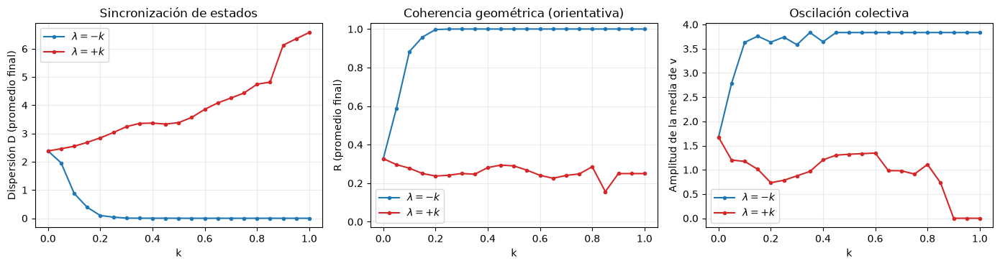

In [3]:
I_FIJO = 0.6
resultados = {}
for signo in (-1, +1):
    for k in K_VALORES:
        sol = simular(lam=signo*float(k), corriente=I_FIJO)
        resultados[(signo, float(k))] = metricas(sol, I_FIJO)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for signo, etiqueta, color in [(-1, r'$\lambda=-k$', 'C0'), (+1, r'$\lambda=+k$', 'C3')]:
    ms = [resultados[(signo, float(k))] for k in K_VALORES]
    axes[0].plot(K_VALORES, [m['D_final'] for m in ms], '-o', ms=3, label=etiqueta, color=color)
    axes[1].plot(K_VALORES, [m['R_final'] for m in ms], '-o', ms=3, label=etiqueta, color=color)
    axes[2].plot(K_VALORES, [m['amplitud_media'] for m in ms], '-o', ms=3, label=etiqueta, color=color)
axes[0].set(title='Sincronización de estados', ylabel='Dispersión D (promedio final)', xlabel='k')
axes[1].set(title='Coherencia geométrica (orientativa)', ylabel='R (promedio final)', xlabel='k', ylim=(-.03,1.03))
axes[2].set(title='Oscilación colectiva', ylabel='Amplitud de la media de v', xlabel='k')
for ax in axes: ax.legend()
fig.tight_layout(); plt.show()

## 3. Comparación temporal con una misma condición inicial

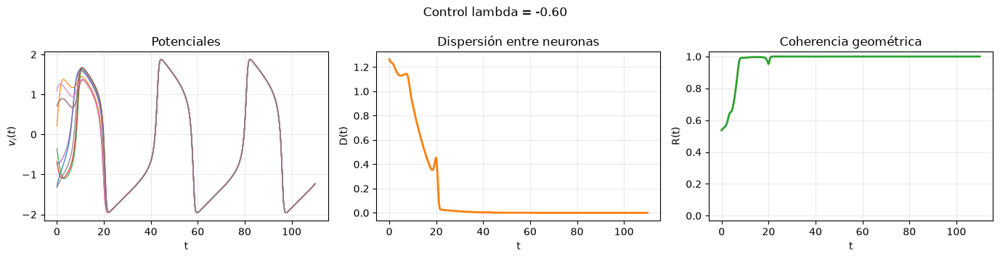

D promedio (último 30%): 0.0000 | R promedio: 1.0000 | amplitud de media v: 3.834


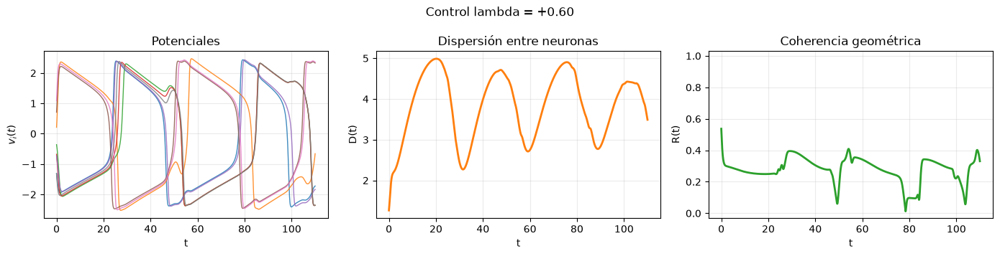

D promedio (último 30%): 3.8554 | R promedio: 0.2408 | amplitud de media v: 1.346


In [4]:
k_ejemplo = 0.6
for signo in (-1, +1):
    lam = signo*k_ejemplo
    sol = simular(lam=lam, corriente=I_FIJO)
    curvas_ejemplo(sol, f'Control lambda = {lam:+.2f}', I_FIJO)

## 4. Explorar interactivamente el barrido
Si `ipywidgets` está instalado, selecciona $k$ y el signo del control. No hace falta recalcular el barrido al inicio; la vista vuelve a simular cada elección.

In [5]:
def explorar_lambda(k=0.5, signo='-k (atractivo)'):
    lam = (-1 if signo.startswith('-') else 1)*float(k)
    sol = simular(lam=lam, corriente=I_FIJO)
    curvas_ejemplo(sol, f'Lambda={lam:+.2f} | I={I_FIJO}', I_FIJO)

if HAY_WIDGETS:
    interact(explorar_lambda,
             k=widgets.SelectionSlider(options=np.round(K_VALORES, 2).tolist(), value=0.5, description='k'),
             signo=widgets.Dropdown(options=['-k (atractivo)', '+k (repulsivo)'], description='Signo'))
else:
    print('Falta ipywidgets; se muestra un caso fijo. Instala: pip install ipywidgets')
    explorar_lambda()

interactive(children=(SelectionSlider(description='k', index=10, options=(0.0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3…

## 5. Animación del plano de fases
Al ejecutar esta celda aparece un reproductor interactivo (play/pausa y avance) incrustado en el notebook. Puede tardar algunos segundos al generarse. **No guarda archivos.**

In [6]:
sol_animacion = simular(lam=-0.6, corriente=I_FIJO)
display(animar_plano(sol_animacion, titulo='8 neuronas: lambda=-0.6, I=0.6'))

In [7]:
sol_animacion = simular(lam=0.6, corriente=I_FIJO)
display(animar_plano(sol_animacion, titulo='8 neuronas: lambda=0.6, I=0.6'))

## 6. Interpretación

- Con el **signo del enunciado**, $\lambda=-k$ es difusivo atractivo. Para grafos conexos, se puede justificar analíticamente la sincronización si la intensidad supera una cota suficiente.
- $\lambda=+k$ es repulsivo en la parte de acoplamiento, pero eso **no prueba** que el sistema completo se desincronice para todo $k$.
- Las gráficas respaldan o contradicen la **hipótesis numérica para estos parámetros y estas condiciones iniciales**, no constituyen una prueba matemática global.
- Experimenta modificando `N`, `A`, `PARAM`, `I_FIJO`, `T_FINAL` y `X0` en las celdas correspondientes (si cambias `T_FINAL`, actualiza `T_EVAL`).